# **CK001 | PfRON4 Co-immunoprecipitation**

Masja Hoogendoorn · Swiss TPH

---

## 00. Overview

RON4 is part of the rhoptry neck complex, which helps *Plasmodium falciparum* merozoites invade red blood cells. To investigate proteins associated with RON4, we performed co-immunoprecipitation (co-IP) followed by LC-MS/MS.

The experiment compares a tagged RON4 line treated with either DMSO or rapamycin, alongside an untagged NF54 line used as a negative control.

| Section | Question | Analysis |
|---|---|---|
| 01 | Are the data and sample assignments correct? | Data validation |
| 02 | What was measured, and how consistent are the runs? | Data quality |
| 03 | Was RON4 successfully recovered? | Bait recovery |
| 04 | How does protein recovery differ between conditions? | MA plots |

Each condition contains one biological preparation measured twice by mass spectrometry. The comparisons are therefore descriptive, without statistical significance testing.

---

## 01. Setup

This section defines the samples, bait protein, statistical thresholds and figure settings used throughout the notebook. These can be changed here without modifying the analysis code.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Locate the project directory, whether this runs from notebooks/ or the root.
PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent

SOURCE_DIR = PROJECT / "src"
if not (SOURCE_DIR / "coip").is_dir():
    raise FileNotFoundError(f"cannot find src/coip in {PROJECT}")
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

from coip import data, figures, processing, saint
# saint is imported for count_summary, the spectra per run in section 02.1.
# CK001 runs no SAINTexpress scoring; output/CK001/README.md says why.

figures.use_style()

In [2]:
EXPERIMENT = "CK001"
WORKBOOK = PROJECT / "input" / EXPERIMENT / "list_of_identified_proteins.xlsx"

OUTPUT = PROJECT / "output" / EXPERIMENT
FIGURE_DIR, TABLE_DIR = OUTPUT / "figures", OUTPUT / "tables"

# Confirmed sample assignments. The two runs per condition are technical
# replicates: one biological preparation, measured twice.
CONDITIONS = {"DMSO": ["001", "003"],
              "RAPA": ["002", "004"],
              "NF54": ["005", "006"]}
REPLICATE_TYPE = "technical"
TREATMENT, REFERENCE, BACKGROUND = "RAPA", "DMSO", "NF54"

SAMPLES = [s for group in CONDITIONS.values() for s in group]
CONDITION_OF = {s: c for c, group in CONDITIONS.items() for s in group}

# The bait, and the invasion-associated proteins followed through the notebook.
BAIT, BAIT_NAME = "Q8IIK5", "RON4"
FOCUS_PROTEINS = {"Q8IIK5": "RON4", "Q8IKV6": "RON2", "Q8I4R5": "RON3",
                  "C0H4V4": "RON5", "Q7KQK5": "AMA1"}
# Row order, top to bottom, in the measurement panel of the main figure.
FOCUS_ROW_ORDER = ["RON4", "RON2", "RON5", "AMA1", "RON3"]

# Median equalisation covers only the four pull-downs being compared; NF54 is a
# different kind of sample and stays out of it.
NORMALISE_SAMPLES = CONDITIONS[REFERENCE] + CONDITIONS[TREATMENT]
MIN_OBSERVATIONS = 2     # per condition, for a complete-case fold change
LOG2FC_CUTOFF = 1.0      # twofold, a magnitude for ranking and never a test

# Section 03: a protein never quantified in NF54 has no difference to report,
# so it is listed by its detection pattern instead of being given a number.
MIN_CONTROLS_TO_RANK = 1 # a difference needs at least this many NF54 values
TOP_N_RECOVERY = 10      # rows in the ranked recovery figure

# Condition colours, all from the Okabe-Ito palette: green is the negative
# control and blue the untreated pull-down, both as elsewhere in the project,
# with orange for the treated pull-down in place of the project's vermillion.
COLOURS = {"DMSO": figures.PULLDOWN_COLOUR,
           "RAPA": figures.OKABE_ITO["orange"],
           "NF54": figures.CONTROL_COLOUR}
# The proteins a figure is about, where they are not the bait itself.
SELECTED_COLOUR = figures.OKABE_ITO["sky"]

FIGURES, TABLES = {}, {}

def save_figure(fig, name, panel_axes=None):
    FIGURES[name] = figures.save(fig, name, FIGURE_DIR, panel_axes=panel_axes)

def save_table(frame, name):
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
    frame.to_csv(TABLE_DIR / f"{name}.csv", index=False)
    TABLES[name] = f"{name}.csv"

print(f"{EXPERIMENT}, bait {BAIT_NAME} ({BAIT})")
for condition, group in CONDITIONS.items():
    print(f"  {condition:5s} runs {', '.join(group)}  ({REPLICATE_TYPE} replicates)")
print("output folder:", OUTPUT)

CK001, bait RON4 (Q8IIK5)
  DMSO  runs 001, 003  (technical replicates)
  RAPA  runs 002, 004  (technical replicates)
  NF54  runs 005, 006  (technical replicates)
output folder: /scicore/home/branic00/hoogen0000/thesis/proteomics/Co-IPs/output/CK001


### Loading the data
The data are loaded from a ProteoFlux workbook and checked before analysis.

In [3]:
workbook = data.load_workbook(WORKBOOK, SAMPLES)

raw_intensity = workbook.intensity
log2_raw = processing.log2_intensities(raw_intensity)
counts = workbook.evidence("Spectral Counts")   # section 02.1, spectra per run

BAIT_ROW = workbook.row_of(BAIT)
FOCUS_ROWS = {accession: workbook.row_of(accession) for accession in FOCUS_PROTEINS}
focus_rows = [FOCUS_ROWS[a] for a in FOCUS_PROTEINS]
ordered_rows = [FOCUS_ROWS[a] for name in FOCUS_ROW_ORDER
                for a in FOCUS_PROTEINS if FOCUS_PROTEINS[a] == name]

save_table(pd.DataFrame(workbook.checks), "qc_validation_checks")

print(f"{len(workbook.annotation):,} protein groups across {len(SAMPLES)} runs")
for sample in SAMPLES:
    print(f"  {sample}  {CONDITION_OF[sample]:5s}  {workbook.column_map[sample]}")
print("input SHA-256:", workbook.sha256)

1,802 protein groups across 6 runs
  001  DMSO   Raw_Intensities001_CK001_G26
  003  DMSO   Raw_Intensities003_CK001_G26
  002  RAPA   Raw_Intensities002_CK001_G26
  004  RAPA   Raw_Intensities004_CK001_G26
  005  NF54   Raw_Intensities005_CK001_G26
  006  NF54   Raw_Intensities006_CK001_G26
input SHA-256: efba217897061154baadabb97489910ced987d1349e9af1735feb2eff7e573a7


---

## 02. Data quality

Before comparing RON4 pull-downs with controls, we examine the quality of the MS measurements and the differences between runs.

### 02.1 Measurement depth

The number of identified spectra and quantified proteins can vary between MS runs. These differences may affect comparisons between samples.

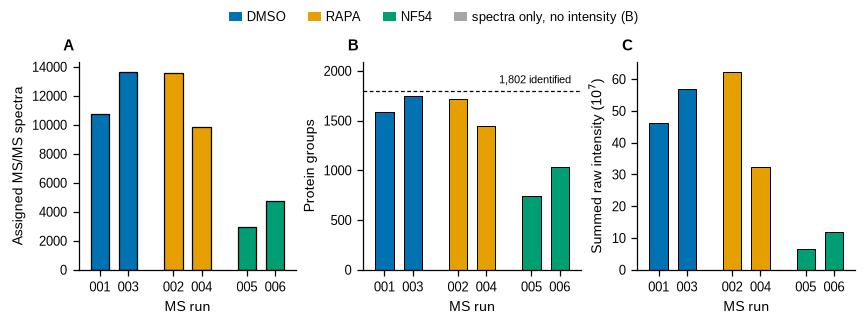

,condition,total_spectra,groups_with_spectra,groups_quantified,total_intensity,missing_fraction
run,,,,,,
001,DMSO,10729,1587,1586,4.611131e+08,0.120
003,DMSO,13657,1752,1751,5.674427e+08,0.028
002,RAPA,13544,1720,1715,6.231820e+08,0.048
004,RAPA,9855,1447,1446,3.232076e+08,0.198
005,NF54,2945,745,745,6.639747e+07,0.587
006,NF54,4736,1038,1036,1.179890e+08,0.425


In [4]:
depth = (data.detection_summary(raw_intensity, CONDITION_OF)
         .rename(columns={"sample": "run", "quantified": "groups_quantified"}))
spectra = (saint.count_summary(counts, CONDITION_OF)
           .rename(columns={"sample": "run",
                            "proteins_with_spectra": "groups_with_spectra"}))
depth = depth.merge(spectra[["run", "total_spectra", "groups_with_spectra"]],
                    on="run", validate="one_to_one")
depth["total_intensity"] = [float(raw_intensity[r].sum()) for r in depth["run"]]
depth["median_log2"] = [float(log2_raw[r].median()) for r in depth["run"]]

N_IDENTIFIED = len(workbook.annotation)
save_table(depth, "qc_measurement_depth")

fig, axes = figures.measurement_depth(depth, CONDITION_OF, COLOURS, N_IDENTIFIED,
                                      run_order=SAMPLES)
save_figure(fig, "01_measurement_depth", panel_axes=axes)
plt.show()

display(depth.set_index("run")[["condition", "total_spectra", "groups_with_spectra",
                                "groups_quantified", "total_intensity",
                                "missing_fraction"]].round(3))

**Figure 1. Measurement depth across runs** The figure compares the number of assigned MS/MS spectra (A), quantified protein groups (B) and summed raw intensity (C) across the six runs. The dashed line in B marks the 1,802 protein groups identified in the experiment as a whole; the grey cap on each bar shows groups with spectra but no usable intensity, at most five per run. The two NF54 runs are the shallowest on all three measures, with 2,945 and 4,736 spectra against 9,855 to 13,657 in the tagged runs. Comparisons against NF54 are therefore affected by measurement depth.

### 02.2 Missing measurements

Not every protein group is quantified in every run. We examine how often measurements are missing and whether this depends on protein abundance.


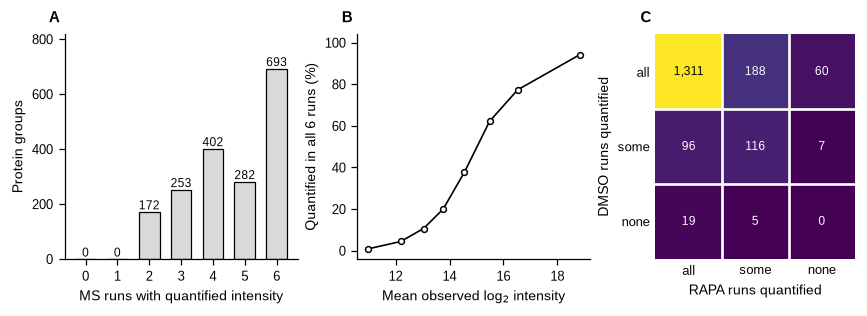

In [5]:
n_quantified = raw_intensity[SAMPLES].notna().sum(axis=1)
detection_frequency = (n_quantified.value_counts()
                       .reindex(range(len(SAMPLES) + 1), fill_value=0).sort_index()
                       .rename_axis("runs_detected")
                       .reset_index(name="protein_groups"))
detection_curve = data.detection_versus_abundance(log2_raw, SAMPLES)

# How completely each of the two compared conditions quantified each group:
# both of its runs, one of them, or neither. NF54 is not in this panel; its
# detection pattern is what section 03 is about.
pattern, _ = data.detection_pattern(raw_intensity, CONDITIONS)
PATTERN_ORDER = ["all", "some", "none"]
pattern_matrix = (pd.crosstab(pattern[REFERENCE], pattern[TREATMENT])
                  .reindex(index=PATTERN_ORDER, columns=PATTERN_ORDER,
                           fill_value=0))

for frame, name in ((detection_frequency, "qc_detection_frequency"),
                    (detection_curve, "qc_detection_versus_abundance"),
                    (pattern_matrix.rename_axis(f"{REFERENCE}_runs")
                     .reset_index(), "qc_detection_pattern")):
    save_table(frame, name)

fig, axes = figures.missingness_overview(
    detection_frequency, detection_curve, pattern_matrix,
    runs_label=f"{len(SAMPLES)} runs",
    condition_labels={"rows": REFERENCE, "columns": TREATMENT})
save_figure(fig, "02_missing_measurements", panel_axes=axes)
plt.show()

**Figure 2. Missing measurements across runs** Panel A shows how many runs each protein group was quantified in, panel B relates detection to protein abundance, and panel C compares detection between DMSO and RAPA. 693 of 1,802 protein groups are quantified in all six runs and none in fewer than two, so the workbook is already filtered. Detection rises with abundance, from 1% of the faintest groups to 94% of the brightest. 1,311 groups are quantified in all four tagged runs and can receive a fold change in Section 04. Missing measurements are not imputed.

### 02.3 Agreement between MS runs
We compare protein intensity patterns between runs to assess how similar the measurements are within and between conditions. The comparison uses the same 693 protein groups quantified in all six runs.

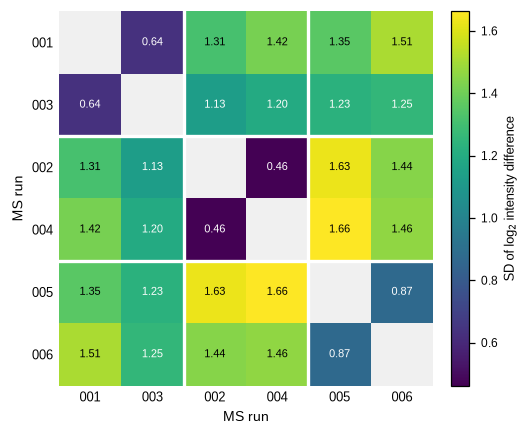

,count,min,max,mean
same_condition,,,,
False,12,1.129,1.663,1.384
True,3,0.462,0.873,0.657


In [6]:
# Every pair must be scored on the same protein groups, so the matrix uses the
# 693 quantified in all six runs rather than whatever each pair happens to share.
COMMON = log2_raw[SAMPLES].notna().all(axis=1)
agreement = data.pair_disagreement(log2_raw.loc[COMMON, SAMPLES])
agreement["same_condition"] = [CONDITION_OF[a] == CONDITION_OF[b]
                               for a, b in zip(agreement["sample_a"],
                                               agreement["sample_b"])]
save_table(agreement, "qc_run_agreement")

replicate_pairs = [(condition, tuple(group))
                   for condition, group in CONDITIONS.items() if len(group) == 2]

fig, ax = figures.run_similarity_grid(agreement, SAMPLES,
                                      block_of=CONDITION_OF,
                                      figsize=(4.4, 3.5))
save_figure(fig, "03_run_similarity")
plt.show()

display(agreement.groupby("same_condition")["sd_log2_difference"]
        .agg(["count", "min", "max", "mean"]).round(3))

**Figure 3. Agreement between MS runs** The heatmap shows the standard deviation of pairwise log₂ intensity differences, calculated on the 693 protein groups quantified in all six runs. Lower values indicate more similar relative intensity patterns. The three repeat injections are the most similar pairs (0.46 for RAPA, 0.64 for DMSO, 0.87 for NF54), compared with 1.13 for the closest pair from different conditions. The NF54 pair agrees least of the three.

### 02.4 Technical replicate variability
The two runs of a condition are repeat injections of one preparation.

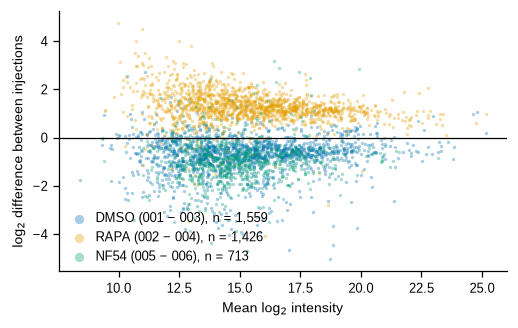

,condition,pair,protein_groups,median,IQR,SD
0,DMSO,001 - 003,1559,-0.638,0.687,0.816
1,RAPA,002 - 004,1426,1.233,0.625,0.676
2,NF54,005 - 006,713,-0.985,0.892,0.880


In [7]:
fig, ax = figures.replicate_difference(log2_raw, replicate_pairs, COLOURS)
save_figure(fig, "04_technical_replicates")
plt.show()

within_pair = pd.DataFrame([
    {"condition": condition, "pair": f"{a} - {b}", "protein_groups": len(both),
     "median": round(float((both[a] - both[b]).median()), 3),
     "IQR": round(float((both[a] - both[b]).quantile(.75)
                        - (both[a] - both[b]).quantile(.25)), 3),
     "SD": round(float((both[a] - both[b]).std()), 3)}
    for condition, (a, b) in replicate_pairs
    for both in [log2_raw[[a, b]].dropna()]])
save_table(within_pair, "qc_replicate_difference")
display(within_pair)

**Figure 4. Difference between the two injections of a preparation** Each point is a protein group quantified in both runs of a pair, plotted at the mean of the two values against their difference. Each pair forms a band offset from zero rather than widening with abundance, so most of the difference is a constant shift per run; the remaining scatter increases towards lower intensities. These are repeat injections of one preparation and describe instrument and injection variability.

---

## 03. Bait recovery
Before identifying potential interaction partners, we check whether RON4 was recovered in the tagged pull-downs compared with the untagged NF54 control.

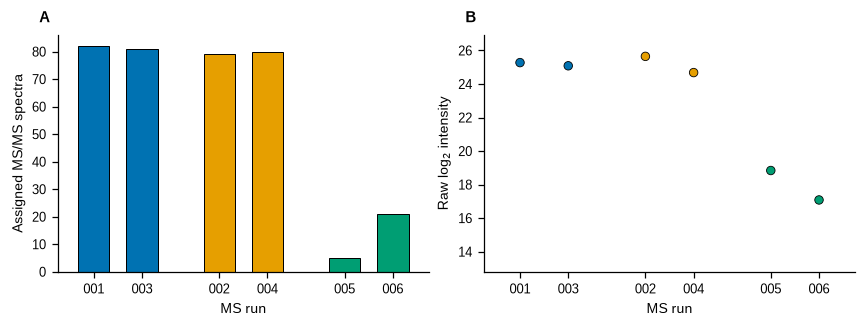

,protein,UNIPROT_AC,NUM_UNIQUE_PEPTIDES,spectra_001,spectra_003,spectra_002,spectra_004,spectra_005,spectra_006
0,RON4,Q8IIK5,45,82,81,79,80,5,21
1,RON2,Q8IKV6,92,137,130,122,96,0,8
2,RON3,Q8I4R5,90,120,112,109,86,4,13
3,RON5,C0H4V4,56,88,84,73,62,0,6
4,AMA1,Q7KQK5;Q94661,32,60,59,57,44,1,6


In [8]:
bait_qc = data.bait_recovery(log2_raw, BAIT_ROW, CONDITION_OF)
bait_qc["spectral_counts"] = counts.loc[BAIT_ROW].to_numpy()
save_table(bait_qc, "qc_bait_recovery")

fig, axes = figures.bait_recovery(bait_qc, COLOURS, run_order=SAMPLES)
save_figure(fig, "05_bait_recovery", panel_axes=axes)
plt.show()

# The evidence behind the five invasion-associated proteins, per run.
evidence = pd.concat(
    [pd.Series([FOCUS_PROTEINS[a] for a in FOCUS_PROTEINS], index=focus_rows,
               name="protein"),
     workbook.annotation.loc[focus_rows, ["UNIPROT_AC", "NUM_UNIQUE_PEPTIDES"]],
     counts.loc[focus_rows].add_prefix("spectra_")], axis=1).reset_index(drop=True)
save_table(evidence, "qc_focus_peptide_evidence")
display(evidence)

**Figure 5. RON4 recovery across runs** Panel A shows the MS/MS spectra assigned to RON4 in each run, panel B its raw log₂ intensity. RON4 was recovered in all four tagged runs with 79 to 82 spectra, where it is the first or second most intense protein group and accounts for 6 to 9% of the run's signal. It is also present in both NF54 runs, with 5 and 21 spectra, since the parental line is untagged rather than RON4-free. The difference between the tagged runs and NF54 is 7.2 log₂.

In [9]:
# Recovery against the untagged line, on the original unnormalised intensities:
# NF54 stays outside the normalisation in section 04.1, so this comparison has
# to be made before it.
n_control = log2_raw[CONDITIONS[BACKGROUND]].notna().sum(axis=1)
mean_control = log2_raw[CONDITIONS[BACKGROUND]].mean(axis=1)   # observed runs only

# Two entries in this search database are fluorescent-tag sequences, not
# parasite proteins. They are ranked like anything else and labelled for what
# they are.
IS_TAG = ~workbook.annotation["FASTA_HEADERS"].astype(str).str.contains("Plasmodium")
description = (workbook.annotation["PROTEIN_DESCRIPTIONS"].astype(str)
               .str.split(";").str[0])
plot_label = pd.Series(
    [FOCUS_PROTEINS.get(str(group).split(";")[0],
                        figures.shorten_name(text, 36) + (" (tag)" if tag else ""))
     for group, text, tag in zip(workbook.annotation["UNIPROT_AC"],
                                 description, IS_TAG)],
    index=log2_raw.index)

# One ranking per tagged condition. Eligible: quantified in both injections of
# that condition and in at least one NF54 run; the other condition is not
# required. A missing NF54 value is not a floor, so a group without one is
# listed with its reason and carries no difference.
condition_ranking, exports = {}, []
for condition in (REFERENCE, TREATMENT):
    runs = CONDITIONS[condition]
    n_tagged = log2_raw[runs].notna().sum(axis=1)
    mean_tagged = log2_raw[runs].mean(axis=1)
    rankable = (n_tagged == len(runs)) & (n_control >= MIN_CONTROLS_TO_RANK)
    reason = pd.Series(f"not quantified in both {condition} runs",
                       index=log2_raw.index)
    reason[rankable] = "ranked"
    reason[(n_tagged == len(runs)) & (n_control == 0)] = (
        f"no {BACKGROUND} measurement, cannot be ranked")
    difference = (mean_tagged - mean_control).where(rankable)
    condition_ranking[condition] = (difference, n_tagged)
    exports.append(pd.DataFrame({
        "condition": condition,
        "protein_group": workbook.annotation["UNIPROT_AC"],
        "label": plot_label, "description": workbook.annotation["PROTEIN_DESCRIPTIONS"],
        "tag_derived": IS_TAG, "is_bait": log2_raw.index == BAIT_ROW,
        f"n_{BACKGROUND}": n_control, "n_condition": n_tagged,
        f"mean_log2_{BACKGROUND}": mean_control.round(3),
        "mean_log2_condition": mean_tagged.round(3),
        "difference_log2": difference.round(3),
        "ranking": reason}).sort_values("difference_log2", ascending=False))
by_condition = pd.concat(exports, ignore_index=True)
by_condition["rank"] = (by_condition.groupby("condition")["difference_log2"]
                        .rank(ascending=False, method="first"))
save_table(by_condition, "qc_ranked_difference_by_condition")

# The pooled ranking over all four tagged runs is kept as a table, for
# reproducibility of the earlier numbers; the figure below is per condition.
n_tagged_all = log2_raw[CONDITIONS[REFERENCE] + CONDITIONS[TREATMENT]].notna().sum(axis=1)
mean_tagged_all = log2_raw[CONDITIONS[REFERENCE] + CONDITIONS[TREATMENT]].mean(axis=1)
rankable_all = (n_tagged_all == 4) & (n_control >= MIN_CONTROLS_TO_RANK)
pooled = pd.DataFrame({
    "protein_group": workbook.annotation["UNIPROT_AC"], "label": plot_label,
    "description": workbook.annotation["PROTEIN_DESCRIPTIONS"], "tag_derived": IS_TAG,
    f"n_{BACKGROUND}": n_control, "n_tagged": n_tagged_all,
    f"mean_log2_{BACKGROUND}": mean_control.round(3),
    "mean_log2_tagged": mean_tagged_all.round(3),
    "difference_log2": (mean_tagged_all - mean_control).where(rankable_all).round(3),
    "is_bait": log2_raw.index == BAIT_ROW,
    "ranking": np.where(rankable_all, "ranked",
                        np.where((n_tagged_all == 4) & (n_control == 0),
                                 f"no {BACKGROUND} measurement, cannot be ranked",
                                 "not quantified in every tagged run"))})
save_table(pooled.sort_values("difference_log2", ascending=False),
           "qc_ranked_difference_vs_control")
save_table(pooled[pooled["ranking"].str.startswith("no ")]
           .sort_values("mean_log2_tagged", ascending=False),
           "qc_recovery_no_control")

# Condition means on the original intensities. Section 04 reuses this for the
# comparison against the normalised values.
recovery_raw = processing.descriptive_comparison(
    log2_raw, CONDITIONS, TREATMENT, REFERENCE, MIN_OBSERVATIONS)

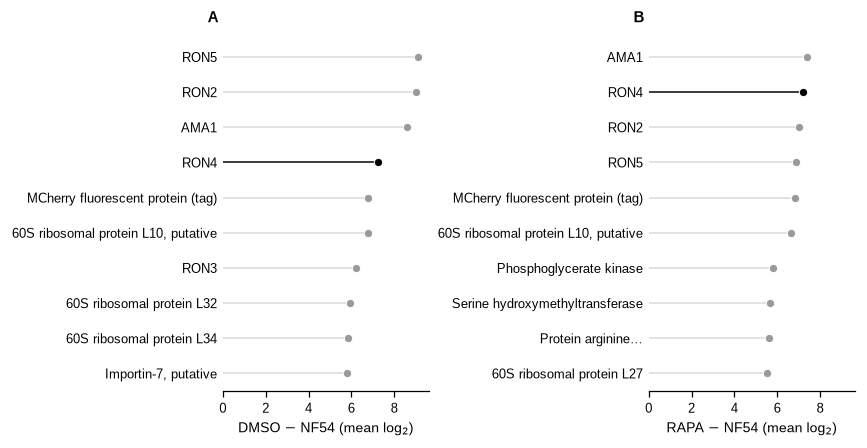

DMSO: 1,021 protein groups rankable; 538 quantified in both DMSO runs but never in NF54
RAPA: 992 protein groups rankable; 434 quantified in both RAPA runs but never in NF54


n_NF54  n_condition  \
condition label                                                      
DMSO      RON5                                      1            2   
          RON2                                      1            2   
          AMA1                                      2            2   
          RON4                                      2            2   
          MCherry fluorescent protein (tag)         1            2   
          60S ribosomal protein L10, putative       2            2   
          RON3                                      2            2   
          60S ribosomal protein L32                 2            2   
          60S ribosomal protein L34                 2            2   
          Importin-7, putative                      1            2   
RAPA      AMA1                                      2            2   
          RON4                                      2            2   
          RON2                                      1            2   
          RON5                                      1            2   
          MCherry fluorescent protein (tag)         1            2   
          60S ribosomal protein L10, putative       2            2   
          Phosphoglycerate kinase                   2            2   
          Serine hydroxymethyltransferase           1            2   
          Protein arginine…                         2            2   
          60S ribosomal protein L27                 2            2   

                                               mean_log2_NF54  \
condition label                                                 
DMSO      RON5                                         15.538   
          RON2                                         15.774   
          AMA1                                         14.406   
          RON4                                         17.961   
          MCherry fluorescent protein (tag)            13.584   
          60S ribosomal protein L10, putative          11.187   
          RON3                                         16.148   
          60S ribosomal protein L32                    11.600   
          60S ribosomal protein L34                    11.680   
          Importin-7, putative                         14.071   
RAPA      AMA1                                         14.406   
          RON4                                         17.961   
          RON2                                         15.774   
          RON5                                         15.538   
          MCherry fluorescent protein (tag)            13.584   
          60S ribosomal protein L10, putative          11.187   
          Phosphoglycerate kinase                      16.225   
          Serine hydroxymethyltransferase              15.454   
          Protein arginine…                            13.582   
          60S ribosomal protein L27                    14.448   

                                               mean_log2_condition  \
condition label                                                      
DMSO      RON5                                              24.631   
          RON2                                              24.778   
          AMA1                                              22.981   
          RON4                                              25.180   
          MCherry fluorescent protein (tag)                 20.359   
          60S ribosomal protein L10, putative               17.949   
          RON3                                              22.345   
          60S ribosomal protein L32                         17.536   
          60S ribosomal protein L34                         17.525   
          Importin-7, putative                              19.878   
RAPA      AMA1                                              21.785   
          RON4                                              25.163   
          RON2                                              22.788   
          RON5           

In [10]:
top_rows = {condition: difference.nlargest(TOP_N_RECOVERY).index
            for condition, (difference, _) in condition_ranking.items()}
widest = max(float(condition_ranking[c][0][rows].max())
             for c, rows in top_rows.items())

fig, axes = plt.subplots(1, 2, figsize=(figures.DOUBLE_COLUMN, 3.6),
                         layout="constrained")
for ax, condition in zip(axes, (REFERENCE, TREATMENT)):
    difference, n_tagged = condition_ranking[condition]
    rows = top_rows[condition]
    figures.enrichment_ranking(
        {condition: difference[rows]}, [plot_label[r] for r in rows],
        colours={condition: figures.BAIT_COLOUR},
        highlight_only=[r == BAIT_ROW for r in rows], series_label=False,
        x_label=f"{condition} $-$ {BACKGROUND} (mean log$_2$)", ax=ax)
    ax.set_xlim(0, widest * 1.06)
    ax.tick_params(axis="y", labelsize=8)
    ax.xaxis.label.set_size(8.5)
save_figure(fig, "05b_top10_recovery", panel_axes=axes)
plt.show()

for condition in (REFERENCE, TREATMENT):
    panel = by_condition[by_condition["condition"] == condition]
    ranked = int((panel["ranking"] == "ranked").sum())
    no_control = int(panel["ranking"].str.startswith("no ").sum())
    print(f"{condition}: {ranked:,} protein groups rankable; {no_control:,} "
          f"quantified in both {condition} runs but never in {BACKGROUND}")
display(by_condition[by_condition["ranking"] == "ranked"]
        .groupby("condition").head(TOP_N_RECOVERY)
        .set_index(["condition", "label"])[
            [f"n_{BACKGROUND}", "n_condition", f"mean_log2_{BACKGROUND}",
             "mean_log2_condition", "difference_log2"]])

**Figure 5b. Recovery relative to NF54, by condition** The ten protein groups with the largest difference between their mean raw log₂ intensity in a tagged condition and in NF54: DMSO (A) and RAPA (B). Each panel is ranked on its own condition, so the two lists contain different proteins. A group is included when it was quantified in both injections of that condition and in at least one NF54 run; groups without an NF54 measurement receive no difference and are listed, with their detection counts, in `qc_ranked_difference_by_condition.csv`. RON4 is shown in black. Invasion-associated proteins and mCherry occupy most of both lists, together with 60S ribosomal proteins, which are common background in affinity purifications. NF54 quantified 745 and 1,036 protein groups against 1,446 to 1,751 in the tagged runs, so these differences reflect measurement depth as well as recovery. The rankings are descriptive, and a difference in rank between the panels does not establish a treatment effect.

---

## 04. Descriptive condition comparison

We compare protein recovery between the DMSO and RAPA pull-downs, using the fold change between the two conditions and the individual measurements behind it.

### 04.1 Normalisation
The four tagged runs differ in how much material reached the instrument, which shifts a whole run up or down. Median equalisation adds one constant per run so that their medians coincide, assuming that the bulk of the eluate is comparable between them. NF54 is excluded, because Section 03 compares against it on the original scale. The correction removes a systematic offset between runs; it does not reduce the variability of the measurements.

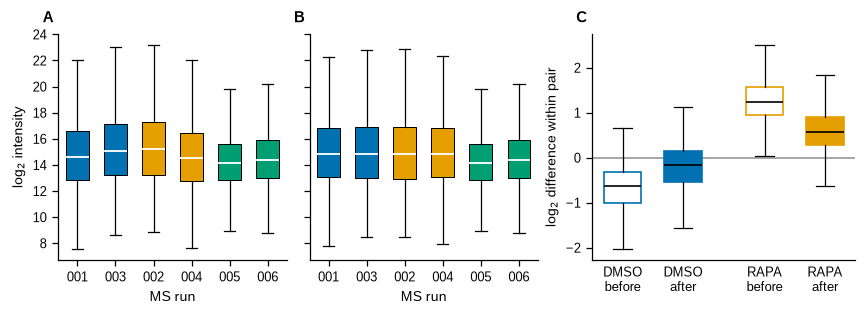

,run,condition,normalised,median_log2_before,offset_log2,median_log2_after
0,001,DMSO,True,14.5822,0.2499,14.8320
1,003,DMSO,True,15.0498,-0.2177,14.8320
2,002,RAPA,True,15.1824,-0.3504,14.8320
3,004,RAPA,True,14.5138,0.3183,14.8320
4,005,NF54,False,14.1278,0.0000,14.1278
5,006,NF54,False,14.3668,0.0000,14.3668


In [11]:
log2_normalised, offsets = processing.median_equalise(log2_raw, NORMALISE_SAMPLES)

normalisation_table = pd.DataFrame({
    "run": SAMPLES,
    "condition": [CONDITION_OF[s] for s in SAMPLES],
    "normalised": [s in NORMALISE_SAMPLES for s in SAMPLES],
    "median_log2_before": log2_raw[SAMPLES].median().round(4).to_numpy(),
    "offset_log2": offsets[SAMPLES].round(4).to_numpy(),
    "median_log2_after": log2_normalised[SAMPLES].median().round(4).to_numpy()})
save_table(normalisation_table, "normalisation_offsets")

fig, axes = figures.normalisation(log2_raw, log2_normalised, SAMPLES,
                                  CONDITION_OF, COLOURS,
                                  replicate_pairs=replicate_pairs[:2])
save_figure(fig, "06_normalisation", panel_axes=axes)
plt.show()

# What the correction did to the difference between two injections of one
# preparation, which is the thing it is aimed at.
within_pair = pd.DataFrame([
    {"condition": condition, "pair": f"{a} - {b}", "stage": stage,
     "protein_groups": int(len(pair)),
     "median": round(float((pair[a] - pair[b]).median()), 4),
     "IQR": round(float((pair[a] - pair[b]).quantile(.75)
                        - (pair[a] - pair[b]).quantile(.25)), 4),
     "SD": round(float((pair[a] - pair[b]).std()), 4)}
    for condition, (a, b) in replicate_pairs[:2]
    for stage, table in (("before", log2_raw), ("after", log2_normalised))
    for pair in [table[[a, b]].dropna()]])
save_table(within_pair, "normalisation_within_pair_offsets")
display(normalisation_table)

**Figure 6. Protein intensities before and after normalisation** Panels A and B show the intensity distribution of each run before and after median equalisation. The four tagged medians coincide at 14.83 after the correction, while the NF54 runs are unchanged. Panel C shows the difference between the two injections of a preparation, before (open) and after (filled), for the proteins quantified in both runs of that pair. Both pairs move towards zero, DMSO from a median of −0.638 to −0.170 and RAPA from +1.233 to +0.564, while the IQR is unchanged at 0.687 and 0.625. The correction removes a constant offset between runs and does not reduce the spread within a pair.

### 04.2 Recovery between DMSO and RAPA
The fold change is the difference between the two condition means on the log₂ scale, positive where more protein was recovered under RAPA. No statistical test is applied, because each condition is a single preparation. Only protein groups quantified in both runs of both conditions receive a fold change; the others are reported by their detection pattern.

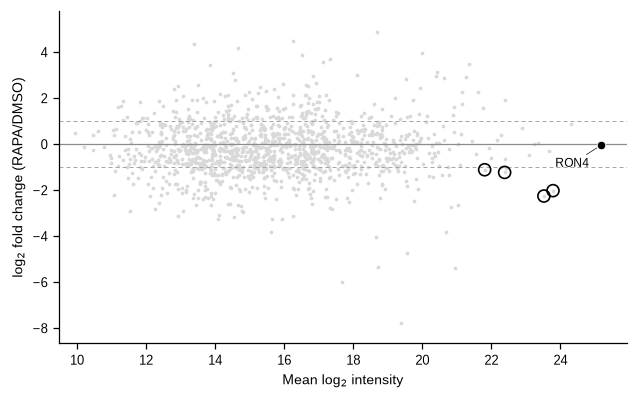

log2 fold change = log2(RAPA / DMSO); positive is more recovered under RAPA
Complete-case fold changes: 1,311 of 1,802 protein groups
Median fold change: -0.229 log2. At least 2x more in RAPA: 173; at least 2x less: 266


In [12]:
recovery = processing.descriptive_comparison(
    log2_normalised, CONDITIONS, TREATMENT, REFERENCE, MIN_OBSERVATIONS)

labels = [FOCUS_PROTEINS.get(str(group).split(";")[0],
                             (str(gene).split(";")[0] or str(group).split(";")[0]))
          for group, gene in zip(workbook.annotation["UNIPROT_AC"],
                                 workbook.annotation["GENE_NAMES"])]
ma_table = recovery.copy()
ma_table["label"] = labels

fig, ax = plt.subplots(figsize=(figures.SINGLE_COLUMN * 1.55, 3.2))
figures.ma_plot(ma_table, highlight_rows=focus_rows, bait_row=BAIT_ROW,
                fold_change_line=LOG2FC_CUTOFF, label_rows=[BAIT_ROW],
                y_label=f"log$_2$ fold change ({TREATMENT}/{REFERENCE})", ax=ax)
save_figure(fig, "07_differential_recovery")
plt.show()

print(f"log2 fold change = log2({TREATMENT} / {REFERENCE}); positive is more "
      f"recovered under {TREATMENT}")
print(f"Complete-case fold changes: {int(recovery.quantified_in_both.sum()):,} "
      f"of {len(recovery):,} protein groups")
print(f"Median fold change: {recovery.log2FC.median():+.3f} log2. "
      f"At least {2 ** LOG2FC_CUTOFF:g}x more in {TREATMENT}: "
      f"{int((recovery.log2FC >= LOG2FC_CUTOFF).sum()):,}; "
      f"at least {2 ** LOG2FC_CUTOFF:g}x less: "
      f"{int((recovery.log2FC <= -LOG2FC_CUTOFF).sum()):,}")

**Figure 7. Recovery between DMSO and RAPA** Mean log₂ intensity against log₂ fold change for the 1,311 protein groups quantified in all four tagged runs, using the median-equalised intensities. Positive values indicate higher recovery under RAPA. RON4 is shown in black and the four other invasion-associated proteins are circled. Dashed lines indicate a twofold difference. The distribution sits slightly below zero across the whole abundance range, while RON4 is close to zero, so a similar amount of bait was recovered in both conditions. Many background proteins also change by more than twofold.

In [13]:
both = recovery["log2FC"].notna() & recovery_raw["log2FC"].notna()
shift = (recovery["log2FC"] - recovery_raw["log2FC"])[both]
sign_changed = both & (np.sign(recovery["log2FC"]) != np.sign(recovery_raw["log2FC"]))

display(pd.DataFrame([
    {"quantity": "offsets applied to runs " + ", ".join(NORMALISE_SAMPLES),
     "value": ", ".join(f"{offsets[s]:+.3f}" for s in NORMALISE_SAMPLES)},
    {"quantity": "shift in log2FC (min, max)",
     "value": f"{shift.min():+.4f}, {shift.max():+.4f}"},
    {"quantity": "Spearman correlation of fold-change ranks",
     "value": f"{recovery.log2FC.rank().corr(recovery_raw.log2FC.rank()):.4f}"},
    {"quantity": "protein groups changing sign",
     "value": f"{int(sign_changed.sum())}, all within "
              f"{recovery.log2FC[sign_changed].abs().max():.3f} log2 of zero"}]))

comparison = pd.DataFrame({
    "protein_group": workbook.annotation["UNIPROT_AC"],
    "description": workbook.annotation["PROTEIN_DESCRIPTIONS"],
    "log2FC_normalised": recovery["log2FC"],
    "log2FC_raw": recovery_raw["log2FC"]})
save_table(comparison, "normalisation_sensitivity")
display(comparison.loc[ordered_rows])

,quantity,value
0,"offsets applied to runs 001, 003, 002, 004","+0.250, -0.218, -0.350, +0.318"
1,"shift in log2FC (min, max)","-0.0322, -0.0321"
2,Spearman correlation of fold-change ranks,1.0000
3,protein groups changing sign,"17, all within 0.030 log2 of zero"


,protein_group,description,log2FC_normalised,log2FC_raw
0,Q8IIK5,Rhoptry neck protein 4,-0.0488,-0.0166
2,Q8IKV6,Rhoptry neck protein 2,-2.0216,-1.9895
3,C0H4V4,Rhoptry neck protein 5,-2.2553,-2.2231
17,Q7KQK5;Q94661,Apical membrane antigen 1,-1.2284,-1.1963
26,Q8I4R5,Rhoptry neck protein 3,-1.1130,-1.0809


Normalisation shifts every fold change by the same constant, because the four offsets leave one fixed difference between the two condition means. The ranking of proteins is unchanged, and the few sign changes occur in proteins close to zero.

The normalised values are used in the figures above. The raw comparison is kept in `normalisation_sensitivity.csv`.

### 04.3 The invasion-associated proteins
RON4 is recovered similarly in both conditions. Panel B therefore compares each protein's change between conditions with RON4's own change.

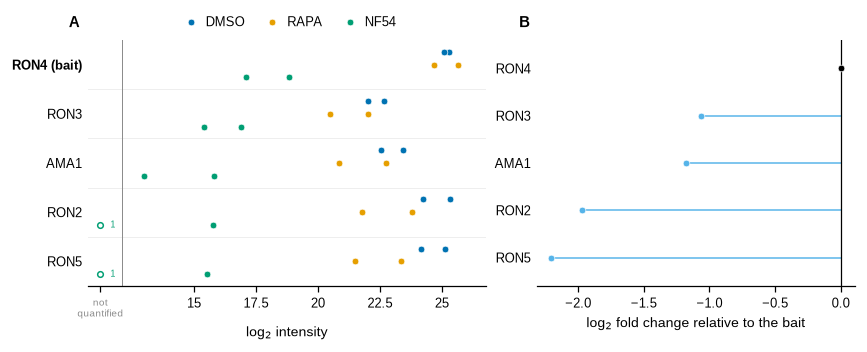

,label,log2FC,log2FC_raw,log2FC_relative_to_bait
0,RON4,-0.0488,-0.0166,0.0000
26,RON3,-1.1130,-1.0809,-1.0642
17,AMA1,-1.2284,-1.1963,-1.1796
2,RON2,-2.0216,-1.9895,-1.9728
3,RON5,-2.2553,-2.2231,-2.2065


In [14]:
# Everything the two panels need, for every protein group.
selected = pd.DataFrame({
    "protein_group": workbook.annotation["UNIPROT_AC"],
    "gene_names": workbook.annotation["GENE_NAMES"],
    "description": workbook.annotation["PROTEIN_DESCRIPTIONS"],
    "label": labels}).join(recovery)
selected["log2FC_raw"] = recovery_raw["log2FC"]
# Each protein's change between conditions, minus the bait's own change.
selected["log2FC_relative_to_bait"] = (
    recovery["log2FC"] - recovery.at[BAIT_ROW, "log2FC"]).round(4)
for sample in SAMPLES:
    selected[f"spectra_{sample}"] = counts[sample]

# Both panels run in the same order, the one panel B sorts into, so a row can
# be followed straight across the figure.
panel_order = figures.bait_relative_order(selected, ordered_rows, BAIT_ROW)
panel_labels = [selected.at[row, "label"] for row in panel_order]

fig, axes = plt.subplots(1, 2, figsize=(figures.DOUBLE_COLUMN, 2.8),
                         gridspec_kw=dict(width_ratios=[1.25, 1]))
# Panel A is on the raw scale: NF54 is shown beside the tagged runs and the
# normalisation was fitted to the tagged runs alone.
figures.protein_recovery(log2_raw, panel_order, panel_labels,
                         CONDITION_OF, COLOURS, CONDITIONS, BAIT_ROW, ax=axes[0])
figures.bait_relative(selected, panel_order, BAIT_ROW, panel_order, ax=axes[1],
                      sort=False, highlight_colour=SELECTED_COLOUR)
save_figure(fig, "08_selected_proteins", panel_axes=axes)
plt.show()

focus_table = selected.loc[panel_order, [
    "protein_group", "label", "description",
    "n_observed_DMSO", "n_observed_RAPA", "n_observed_NF54",
    "mean_log2_DMSO", "mean_log2_RAPA", "mean_log2_NF54",
    "log2FC", "log2FC_raw", "log2FC_relative_to_bait",
    *[f"spectra_{s}" for s in SAMPLES]]]
save_table(focus_table, "focus_protein_summary")
display(focus_table[["label", "log2FC", "log2FC_raw",
                     "log2FC_relative_to_bait"]])

**Figure 8. The five invasion-associated proteins** Both panels list the proteins in the same order, sorted by panel B. (A) Every individual measurement on the raw log₂ scale, so that NF54 can be shown beside the tagged runs; the correction in 04.1 was fitted to the tagged runs alone. Within each protein the runs read 001, 003 (DMSO), 002, 004 (RAPA), 005, 006 (NF54), and the two runs of a condition are repeat injections of one preparation. RON2 and RON5 were not quantified in run 005, shown as an open ring rather than a zero. (B) Each protein's fold change between the conditions after subtracting RON4's own. RON2 and RON5 lie about 2 log₂ below the bait and AMA1 and RON3 about 1 log₂, so they were recovered less per unit of bait under RAPA. This describes relative recovery, not binding affinity.